In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
# 1. Cargar y preprocesar el dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [4]:
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

In [5]:
# 2. Definir el modelo
model = Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    Conv2D(32, (3,3), activation='relu', name="conv1"),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu', name="conv2"),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [7]:
# 3. Compilar y entrenar
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 53s 53ms/step - accuracy: 0.9485 - loss: 0.1700 - val_accuracy: 0.9819 - val_loss: 0.0578
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 53ms/step - accuracy: 0.9835 - loss: 0.0544 - val_accuracy: 0.9871 - val_loss: 0.0407
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 51ms/step - accuracy: 0.9882 - loss: 0.0360 - val_accuracy: 0.9882 - val_loss: 0.0354
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 85s 54ms/step - accuracy: 0.9908 - loss: 0.0276 - val_accuracy: 0.9889 - val_loss: 0.0310
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 50s 53ms/step - accuracy: 0.9940 - loss: 0.0185 - val_accuracy: 0.9873 - val_loss: 0.0380
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 87s 59ms/step - accuracy: 0.9944 - loss: 0.0184 - val_accuracy: 0.9912 - val_loss: 0.0297
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 77s 53ms/step - accuracy: 0.9959 - loss: 0.0133 - val_accuracy: 0.9903 - val_loss: 0.0302
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 81s 52ms/step - accuracy: 0.9969 - loss: 0.0108 - 

In [9]:
# 4. Guardar y cargar modelo
model.save("modelo_cnn_mnist.h5")
modelo_cargado = load_model("modelo_cnn_mnist.h5")
print("Modelo guardado y cargado correctamente.")

Modelo guardado y cargado correctamente.


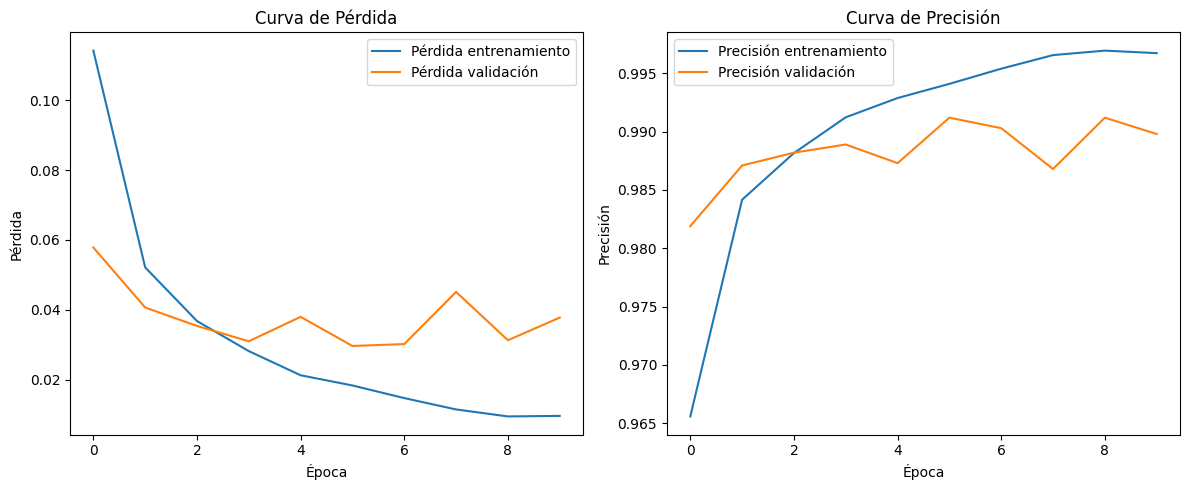

In [10]:
# 5. Visualización de curvas de pérdida y accuracy
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Pérdida entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida validación')
plt.title("Curva de Pérdida")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Precisión entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precisión validación')
plt.title("Curva de Precisión")
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.legend()

plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


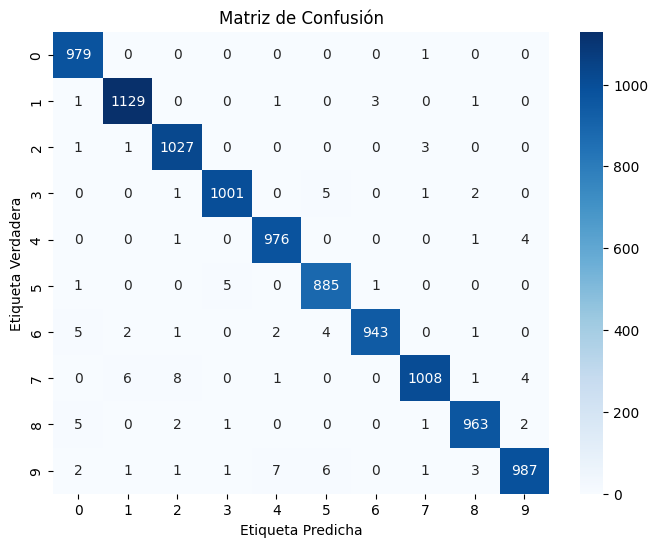


Reporte de Clasificación:

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.99      1.00      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.99       892
           6       1.00      0.98      0.99       958
           7       0.99      0.98      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [11]:
# 6. Evaluación por clase: matriz de confusión
y_pred = np.argmax(model.predict(x_test), axis=-1)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusión")
plt.xlabel("Etiqueta Predicha")
plt.ylabel("Etiqueta Verdadera")
plt.show()

print("\nReporte de Clasificación:\n")
print(classification_report(y_test, y_pred))

In [13]:
# 7. Visualización de activaciones (primeras capas)
from tensorflow.keras import models

In [14]:
# Seleccionar una imagen de prueba
imagen = x_test[0].reshape(1, 28, 28, 1)

In [15]:
# Crear un modelo para obtener salidas intermedias
layer_outputs = [layer.output for layer in model.layers if 'conv' in layer.name]

In [16]:
# Instead of using model.input, we use model.layers[0].input:
activation_model = models.Model(inputs=model.layers[0].input, outputs=layer_outputs)
activations = activation_model.predict(imagen)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


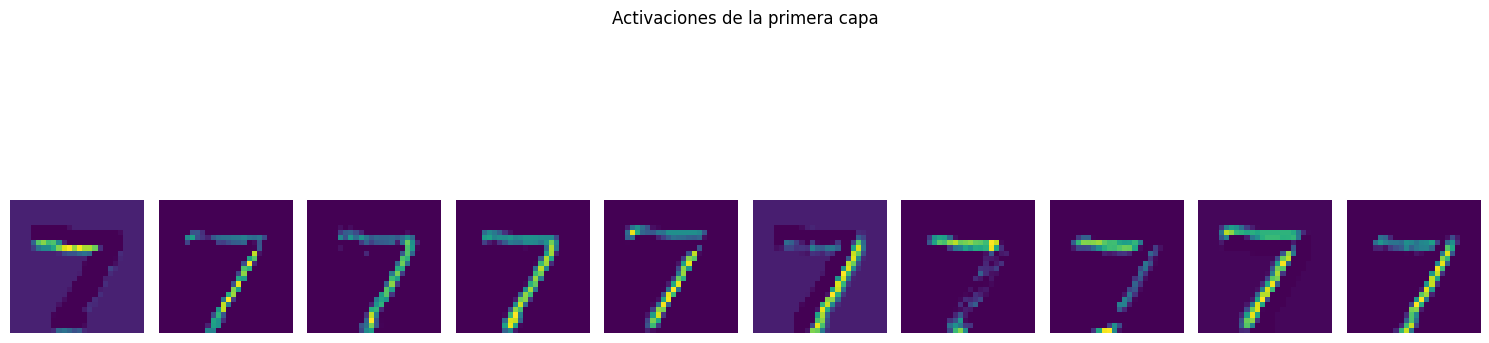

In [17]:
# Visualizar los mapas de activación de la primera capa convolucional
first_layer_activation = activations[0]  # salidas de la primera capa conv
n_features = first_layer_activation.shape[-1]

plt.figure(figsize=(15,5))
for i in range(min(n_features, 10)):
    plt.subplot(1, 10, i+1)
    plt.imshow(first_layer_activation[0, :, :, i], cmap='viridis')
    plt.axis('off')
plt.suptitle("Activaciones de la primera capa")
plt.tight_layout()
plt.show()

# Ejemplo Visualización de Filtros Aprendidos

In [18]:
# Después de entrenar el modelo
import matplotlib.pyplot as plt

In [19]:
filters, biases = model.layers[0].get_weights()

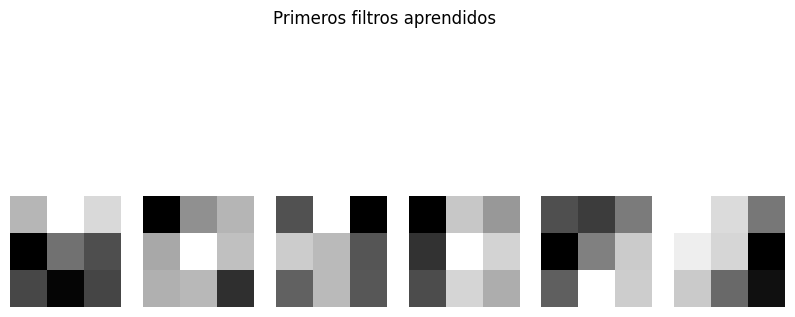

In [20]:
plt.figure(figsize=(10, 5))
for i in range(6):
    f = filters[:, :, 0, i]
    plt.subplot(1, 6, i+1)
    plt.imshow(f, cmap='gray')
    plt.axis('off')
plt.suptitle("Primeros filtros aprendidos")
plt.show()